# Dataset Inspection – EconoCausal

## Objective

The objective of this notebook is to inspect the original iFlex experiment datasets and understand their structure before performing data preparation.

## Datasets

1. experiment_days.csv
2. price_signals.csv
3. data_hourly.csv

## Inspection Tasks

- Load the datasets.
- Examine the number of rows and columns.
- Identify column names and data types.
- Check missing values.
- Check duplicate records.
- Understand the date and price signal structure.

The original raw datasets will remain unchanged.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Define the raw data folder
DATA_DIR = Path("../data/raw")

# Load the two smaller datasets
experiment_days = pd.read_csv(DATA_DIR / "experiment_days.csv")
price_signals = pd.read_csv(DATA_DIR / "price_signals.csv")

# Display dataset information
print("EXPERIMENT DAYS DATASET")
print("Shape:", experiment_days.shape)
print(experiment_days.head())

print("\nPRICE SIGNALS DATASET")
print("Shape:", price_signals.shape)
print(price_signals.head())

EXPERIMENT DAYS DATASET
Shape: (267, 4)
  Participation_Phase Price_signal        Date Group
0             Phase_1         A_10  2020-02-13    H1
1             Phase_1         A_10  2020-03-02    H1
2             Phase_1          A_5  2020-02-14    H1
3             Phase_1          A_5  2020-03-03    H1
4             Phase_1         B_10  2020-03-04    H1

PRICE SIGNALS DATASET
Shape: (336, 5)
  Price_signal Price_profile Price_level  Hour  Experiment_price_NOK_kWh
0         A_10             A          10     1                      1.00
1         A_10             A          10     2                      0.99
2         A_10             A          10     3                      0.95
3         A_10             A          10     4                      0.95
4         A_10             A          10     5                      0.96


In [2]:
# 1. Check missing values
print("EXPERIMENT DAYS - MISSING VALUES")
print(experiment_days.isnull().sum())

print("\nPRICE SIGNALS - MISSING VALUES")
print(price_signals.isnull().sum())


# 2. Check duplicate rows
print("\nEXPERIMENT DAYS - DUPLICATES")
print(experiment_days.duplicated().sum())

print("\nPRICE SIGNALS - DUPLICATES")
print(price_signals.duplicated().sum())


# 3. Check column data types
print("\nEXPERIMENT DAYS - DATA TYPES")
print(experiment_days.dtypes)

print("\nPRICE SIGNALS - DATA TYPES")
print(price_signals.dtypes)


# 4. Check date range
experiment_days["Date"] = pd.to_datetime(
    experiment_days["Date"],
    errors="coerce"
)

print("\nDATE RANGE")
print("Start:", experiment_days["Date"].min())
print("End:", experiment_days["Date"].max())


# 5. Count unique price signals
print("\nUNIQUE PRICE SIGNALS")
print(experiment_days["Price_signal"].nunique())

print("\nPRICE SIGNAL RECORDS")
print(price_signals["Price_signal"].nunique())

print("\nHOURS PER PRICE SIGNAL")
print(price_signals.groupby("Price_signal")["Hour"].nunique())

EXPERIMENT DAYS - MISSING VALUES
Participation_Phase    0
Price_signal           0
Date                   0
Group                  0
dtype: int64

PRICE SIGNALS - MISSING VALUES
Price_signal                0
Price_profile               0
Price_level                 0
Hour                        0
Experiment_price_NOK_kWh    0
dtype: int64

EXPERIMENT DAYS - DUPLICATES
0

PRICE SIGNALS - DUPLICATES
0

EXPERIMENT DAYS - DATA TYPES
Participation_Phase    object
Price_signal           object
Date                   object
Group                  object
dtype: object

PRICE SIGNALS - DATA TYPES
Price_signal                 object
Price_profile                object
Price_level                  object
Hour                          int64
Experiment_price_NOK_kWh    float64
dtype: object

DATE RANGE
Start: 2020-02-11 00:00:00
End: 2021-03-25 00:00:00

UNIQUE PRICE SIGNALS
14

PRICE SIGNAL RECORDS
14

HOURS PER PRICE SIGNAL
Price_signal
A_10     24
A_5      24
B_10     24
B_15     24
B_2      24


In [3]:
# 1. Count experiment days by phase
print("EXPERIMENT DAYS BY PHASE")
print(experiment_days["Participation_Phase"].value_counts())

# 2. Count experiment days by group
print("\nEXPERIMENT DAYS BY GROUP")
print(experiment_days["Group"].value_counts())

# 3. Count experiment days by price signal
print("\nEXPERIMENT DAYS BY PRICE SIGNAL")
print(experiment_days["Price_signal"].value_counts())

# 4. Price statistics by profile
print("\nPRICE STATISTICS BY PROFILE")

profile_stats = price_signals.groupby("Price_profile")[
    "Experiment_price_NOK_kWh"
].agg(["count", "min", "mean", "max"])

print(profile_stats.round(2))

# 5. Price statistics by signal
print("\nPRICE STATISTICS BY SIGNAL")

signal_stats = price_signals.groupby("Price_signal")[
    "Experiment_price_NOK_kWh"
].agg(["min", "mean", "max"])

print(signal_stats.round(2))

EXPERIMENT DAYS BY PHASE
Participation_Phase
Phase_2    254
Phase_1     13
Name: count, dtype: int64

EXPERIMENT DAYS BY GROUP
Group
H1         26
H2         23
Trom_2     21
Trond_1    21
Trom_1     21
Os_6       20
Os_4       20
Os_3       20
Os_1       20
Os_5       20
Os_2       20
Ber_1      19
Bo_1       16
Name: count, dtype: int64

EXPERIMENT DAYS BY PRICE SIGNAL
Price_signal
B_10     40
B_2      35
P_10     30
B_5      30
B_15     28
P_15     20
P_2      16
P_5      15
A_10     12
A_5      11
C        10
P0_10    10
P0_2      5
P0_30     5
Name: count, dtype: int64

PRICE STATISTICS BY PROFILE
               count   min  mean    max
Price_profile                          
A                 48  0.95  4.16  10.13
B                 96  0.95  5.08  15.20
C                 24  0.95  3.95  10.13
P                 96  0.95  1.62  15.08
P0                72  0.00  1.17  30.15

PRICE STATISTICS BY SIGNAL
               min  mean    max
Price_signal                   
A_10          0.95

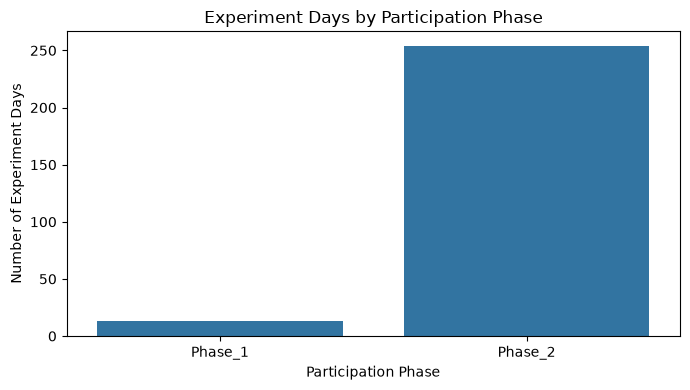

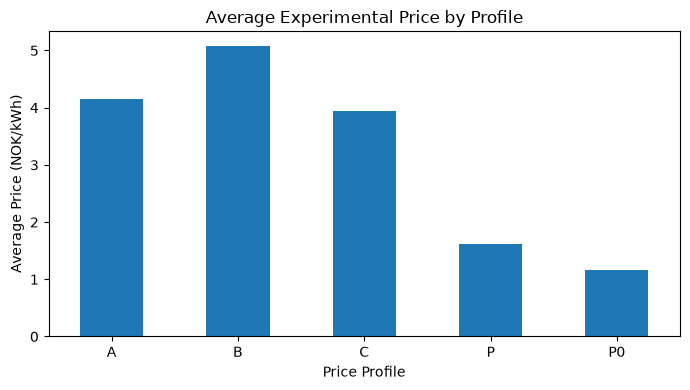

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization 1: Experiment days by phase
plt.figure(figsize=(7, 4))

sns.countplot(
    data=experiment_days,
    x="Participation_Phase"
)

plt.title("Experiment Days by Participation Phase")
plt.xlabel("Participation Phase")
plt.ylabel("Number of Experiment Days")
plt.tight_layout()
plt.show()


# Visualization 2: Average price by profile
profile_mean = price_signals.groupby(
    "Price_profile"
)["Experiment_price_NOK_kWh"].mean()

plt.figure(figsize=(7, 4))

profile_mean.plot(kind="bar")

plt.title("Average Experimental Price by Profile")
plt.xlabel("Price Profile")
plt.ylabel("Average Price (NOK/kWh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Dataset location
DATA_DIR = Path("../data/raw")

# Load datasets
experiment_days = pd.read_csv(DATA_DIR / "experiment_days.csv")
price_signals = pd.read_csv(DATA_DIR / "price_signals.csv")

# Convert date
experiment_days["Date"] = pd.to_datetime(
    experiment_days["Date"]
)

print("Datasets loaded successfully!")
print("Experiment days:", experiment_days.shape)
print("Price signals:", price_signals.shape)

Datasets loaded successfully!
Experiment days: (267, 4)
Price signals: (336, 5)


In [5]:
# Investigate experiment group assignments

print("GROUP VALUES:")
print(experiment_days["Group"].unique())

print("\nNUMBER OF RECORDS BY GROUP:")
print(experiment_days["Group"].value_counts().sort_index())

print("\nGROUPS BY PARTICIPATION PHASE:")
print(
    experiment_days.groupby(
        ["Participation_Phase", "Group"]
    ).size().unstack(fill_value=0)
)

print("\nSAMPLE OF EXPERIMENT DAY RECORDS:")
display(experiment_days.head(15))

GROUP VALUES:
<ArrowStringArray>
[     'H1',      'H2',    'Os_3',    'Os_4',    'Os_6',   'Ber_1',    'Os_1',
 'Trond_1',  'Trom_1',    'Bo_1',    'Os_2',    'Os_5',  'Trom_2']
Length: 13, dtype: str

NUMBER OF RECORDS BY GROUP:
Group
Ber_1      19
Bo_1       16
H1         26
H2         23
Os_1       20
Os_2       20
Os_3       20
Os_4       20
Os_5       20
Os_6       20
Trom_1     21
Trom_2     21
Trond_1    21
Name: count, dtype: int64

GROUPS BY PARTICIPATION PHASE:
Group                Ber_1  Bo_1  H1  H2  Os_1  Os_2  Os_3  Os_4  Os_5  Os_6  \
Participation_Phase                                                            
Phase_1                  0     0   8   5     0     0     0     0     0     0   
Phase_2                 19    16  18  18    20    20    20    20    20    20   

Group                Trom_1  Trom_2  Trond_1  
Participation_Phase                           
Phase_1                   0       0        0  
Phase_2                  21      21       21  

SAMPLE OF EXPE

,Participation_Phase,Price_signal,Date,Group
0,Phase_1,A_10,2020-02-13,H1
1,Phase_1,A_10,2020-03-02,H1
2,Phase_1,A_5,2020-02-14,H1
3,Phase_1,A_5,2020-03-03,H1
4,Phase_1,B_10,2020-03-04,H1
5,Phase_1,B_5,2020-02-11,H1
6,Phase_1,C,2020-02-12,H1
7,Phase_1,C,2020-03-05,H1
8,Phase_1,P_10,2020-02-13,H2
9,Phase_1,P_10,2020-02-19,H2


In [9]:
# Inspect hourly observations on one experiment day

experiment_date = "2020-02-11"
day_records = []

for chunk in pd.read_csv(file_path, chunksize=100_000):

    matching_rows = chunk[
        chunk["Date"] == experiment_date
    ]

    if not matching_rows.empty:
        day_records.append(matching_rows)

day_data = pd.concat(day_records, ignore_index=True)

print("Records on experiment day:", len(day_data))
print("Unique households:", day_data["ID"].nunique())

print("\nPrice signal values:")
print(day_data["Price_signal"].value_counts(dropna=False))

display(day_data.head(10))

Records on experiment day: 17808
Unique households: 742

Price signal values:
Price_signal
NaN    12552
B_5     5256
Name: count, dtype: int64


,ID,From,Date,Hour,Participation_Phase,Demand_kWh,Price_signal,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72
0,Exp_43,2020-02-11T00:00:00Z,2020-02-11,1,Phase_1,0.560,B_5,1.00,3.0,4.2,5.2,5.6
1,Exp_43,2020-02-11T01:00:00Z,2020-02-11,2,Phase_1,0.312,B_5,0.99,3.0,4.1,5.1,5.6
2,Exp_43,2020-02-11T02:00:00Z,2020-02-11,3,Phase_1,0.583,B_5,0.95,3.3,4.0,5.0,5.6
3,Exp_43,2020-02-11T03:00:00Z,2020-02-11,4,Phase_1,0.328,B_5,0.95,3.7,3.9,5.0,5.6
4,Exp_43,2020-02-11T04:00:00Z,2020-02-11,5,Phase_1,0.332,B_5,0.96,4.0,3.8,4.9,5.5
5,Exp_43,2020-02-11T05:00:00Z,2020-02-11,6,Phase_1,0.571,B_5,1.00,3.8,3.8,4.9,5.5
6,Exp_43,2020-02-11T06:00:00Z,2020-02-11,7,Phase_1,1.306,B_5,2.74,3.5,3.7,4.8,5.5
7,Exp_43,2020-02-11T07:00:00Z,2020-02-11,8,Phase_1,1.266,B_5,4.98,3.4,3.6,4.8,5.5
8,Exp_43,2020-02-11T08:00:00Z,2020-02-11,9,Phase_1,0.698,B_5,5.07,3.2,3.6,4.8,5.4
9,Exp_43,2020-02-11T09:00:00Z,2020-02-11,10,Phase_1,0.581,B_5,5.03,3.2,3.5,4.7,5.3


In [10]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/data_hourly.csv")

print("File exists:", file_path.exists())
print("File path:", file_path)

File exists: True
File path: ..\data\raw\data_hourly.csv


# Compare households with and without B_5 on the experiment day

with_signal = set(
    day_data.loc[
        day_data["Price_signal"] == "B_5", "ID"
    ].unique()
)

without_signal = set(
    day_data.loc[
        day_data["Price_signal"].isna(), "ID"
    ].unique()
)

print("Households with B_5:", len(with_signal))
print("Households without B_5:", len(without_signal))

print("\nHouseholds in both categories:",
      len(with_signal.intersection(without_signal)))

print("\nHouseholds only with B_5:",
      len(with_signal - without_signal))

print("\nHouseholds only without B_5:",
      len(without_signal - with_signal))

Households with B_5:
Households without B_5:
Households in both categories:
Households only with B_5:
Households only without B_5:

In [11]:
print("Households with B_5:", len(with_signal))
print("Households without B_5:", len(without_signal))
print("Households in both categories:", len(with_signal.intersection(without_signal)))
print("Households only with B_5:", len(with_signal - without_signal))
print("Households only without B_5:", len(without_signal - with_signal))

NameError: name 'with_signal' is not defined

In [12]:
# Recreate household comparison for B_5

with_signal = set(
    day_data.loc[
        day_data["Price_signal"] == "B_5", "ID"
    ].unique()
)

without_signal = set(
    day_data.loc[
        day_data["Price_signal"].isna(), "ID"
    ].unique()
)

print("Households with B_5:", len(with_signal))
print("Households without B_5:", len(without_signal))

print(
    "Households in both categories:",
    len(with_signal.intersection(without_signal))
)

print(
    "Households only with B_5:",
    len(with_signal - without_signal)
)

print(
    "Households only without B_5:",
    len(without_signal - with_signal)
)

Households with B_5: 219
Households without B_5: 523
Households in both categories: 0
Households only with B_5: 219
Households only without B_5: 523
